# Роль средних центров: население, обычные магазины и получение товаров

## Исследовательский приоритет
Главный исход — изменение относительного места центра в его окружении.
Измеряем отдельно долю населения и концентрацию обычной физической торговли.
Распространение ПВЗ — возможный механизм; количество ПВЗ не заменяет эти исходы.
Сокращение обычных магазинов проверяется, а не задаётся как обязательный результат.

В этом этапе получены частичная история Ozon, адресные магазинные реестры
сельского района 2019–2026 и большой муниципальный слой физических объектов.
Есть фактические изменения, но причинное влияние маркетплейсов ещё не установлено.

## Методы и единицы
Средний центр в основной спецификации: административный центр ОКТМО 2020,
имевший 5000–49999 жителей 2002. Это явная аналитическая конвенция, не измеренный
торговый ранг. Чувствительность к размерным порогам и покрытию сохранена.

Демографическая доля рассчитана на одном фиксированном административном
контексте 2020 и общей межпереписной оси НП с прямыми значениями 2002/2021.
Она характеризует длительный фон, не постэффект ПВЗ. Административное
окружение не является измеренным покупательским ареалом.

Торговая доля C/S — число обычных магазинов нижнего муниципалитета центра
делённое на число магазинов всего района, синхронные IVкварталы 2022–2024.
Во всех четырёх доступных выпусках 2020/2021/2022/2026 нижний МО содержит
единственный тот же НП. Но составы 2023/2024 и неизменность границ не проверены,
поэтому строгая единица результата — муниципальная территория центра;
привязка каждого магазина к НП остаётся условной. Адресный слой Чои даёт
другой, непосредственно поселенческий пример. Ничего не распределяется
между деревнями пропорционально населению.

In [1]:
from pathlib import Path
import contextlib,io,json,runpy
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
assert (ROOT/'system/centre_system_demography.csv').exists()
for file in ['analyze_functional_role.py','relate_receipt_and_trade.py']:
    with contextlib.redirect_stdout(io.StringIO()):
        runpy.run_path(str(ROOT/file),run_name='__main__')
    print('Выполнен:',file)
plt.rcParams.update({'font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False,'axes.axisbelow':True})


Выполнен: analyze_functional_role.py
Выполнен: relate_receipt_and_trade.py


## Демографический вес: исторический фон 2002–2021
Падение собственной численности и потеря доли — разные события.
В основной пригодной подвыборке 1195 центров медиана собственной динамики−11,50%,
но медиана изменения доли+4,06 п.п. Эти интервалы не привязаны к локальным
открытиям маркетплейсов. Изменение роли после 2021 пока не следует из этого фона.

,Категория,Население сократилось,Население выросло/не изменилось
0,Доля выросла ≥1п.п.,752,194
1,Модуль изменения доли <1п.п.,106,35
2,Доля снизилась ≥1п.п.,76,32


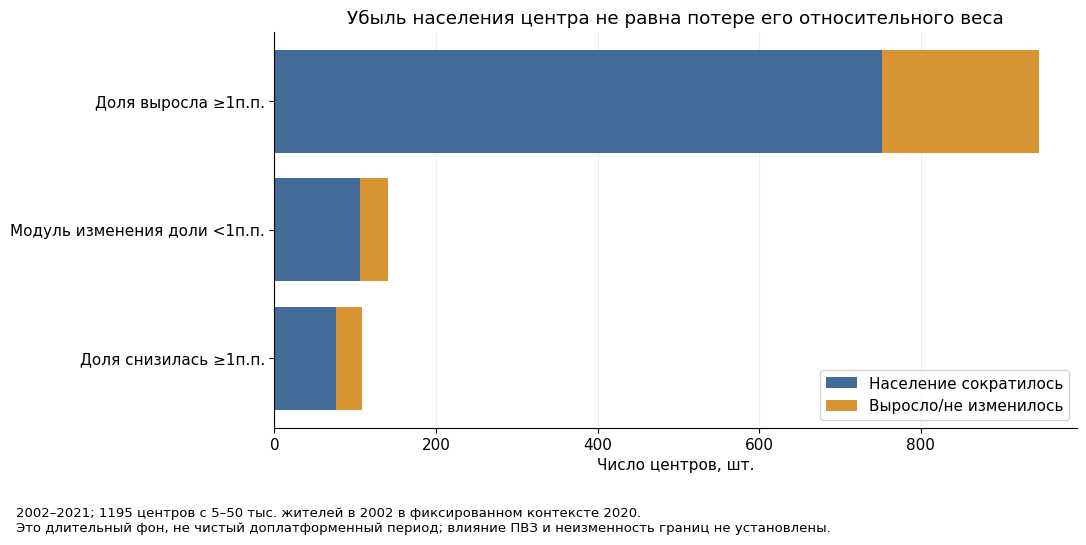

In [2]:
dem=pd.read_csv(ROOT/'system/centre_system_demography.csv')
g=dem[dem.medium_primary2002 & dem.demographic_comparison_supported].copy()
assert len(g)==1195
share=g.centre_population_share_change_pp
decline=g.centre_change2002_2021_pct.lt(0)
rows=[]
for label,mask in [('Доля выросла ≥1п.п.',share.ge(1)),
                   ('Модуль изменения доли <1п.п.',share.abs().lt(1)),
                   ('Доля снизилась ≥1п.п.',share.le(-1))]:
    rows.append({'Категория':label,'Население сократилось':int((mask&decline).sum()),
                 'Население выросло/не изменилось':int((mask&~decline).sum())})
dt=pd.DataFrame(rows)
assert dt.iloc[:,1:].to_numpy().sum()==len(g)
display(dt)
fig,ax=plt.subplots(figsize=(11,5.5))
ax.barh(dt['Категория'],dt['Население сократилось'],color='#426b97',label='Население сократилось')
ax.barh(dt['Категория'],dt['Население выросло/не изменилось'],
        left=dt['Население сократилось'],color='#d79533',label='Выросло/не изменилось')
ax.set_xlabel('Число центров, шт.')
ax.set_title('Убыль населения центра не равна потере его относительного веса')
ax.grid(axis='x',alpha=.2)
ax.invert_yaxis()
ax.legend()
fig.tight_layout()
fig.subplots_adjust(bottom=.21)
fig.text(.02,.02,'2002–2021; 1195 центров с 5–50 тыс. жителей в 2002 в фиксированном контексте 2020.\n'
         'Это длительный фон, не чистый доплатформенный период; влияние ПВЗ и неизменность границ не установлены.',fontsize=9.5)
fig.savefig(ROOT/'population_weight.png',dpi=150)
plt.show()


## Физическая торговля в центре и районе: основной функциональный исход
Источник — показатель количества физических объектов БДПМО в обработке
«Если быть точным», версия 28.09.2026. Он не является числом зарегистрированных
юрлиц. Обычные магазины отделены от общепита, рынков, аптек и АЗС.
Все магазинные подкатегории не суммируются между собой.

Основная панель C/S включает 174 средних центра для «Магазинов»,161 для
специализированных непродовольственных. Это выбранные пригодные случаи,
не репрезентативная оценка по всем центрам России. Годовые строки, IVкварталы,
«На 1 января» и новая номенклатура 2025 не объединяются в один ряд.

,Категория,Центров,Запас сократился,Запас вырос,Не изменился,Доля снизилась,"Медиана Δдоли, п.п."
0,Магазины,174,55,84,35,49,0.88
1,Специализированные непродовольственные магазины,161,43,55,63,39,0.00


,category,share_threshold_pp,centres_n,share_loss_n,share_gain_n,share_between_thresholds_n,centre_stock_decline_n,stock_decline_and_share_loss_n,median_share_change_pp
0,Магазины,0,174,49,117,8,55,32,0.881487
1,Магазины,1,174,26,84,64,55,18,0.881487
2,Магазины,2,174,13,57,104,55,10,0.881487
3,Магазины,5,174,4,14,156,55,3,0.881487
4,Специализированные непродовольственные магазины,0,161,39,41,81,43,25,0.000000
5,Специализированные непродовольственные магазины,1,161,26,26,109,43,13,0.000000
6,Специализированные непродовольственные магазины,2,161,21,19,121,43,9,0.000000
7,Специализированные непродовольственные магазины,5,161,13,6,142,43,3,0.000000


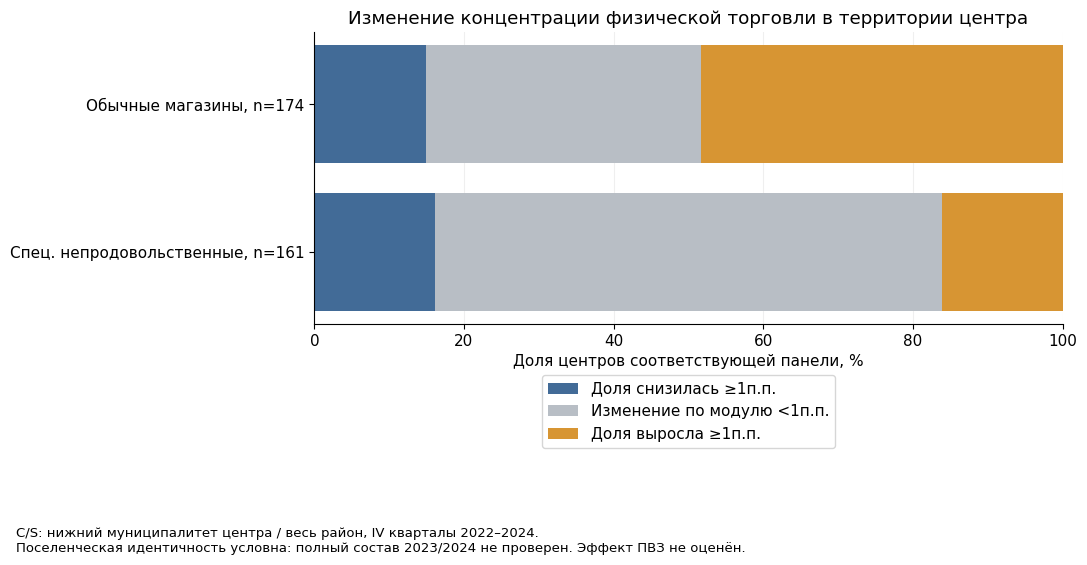

In [3]:
trade=pd.read_csv(ROOT/'bdmo/singleton/internal_centre_district_common_panels2022_2024.csv')
trade=trade[trade.medium_primary2002].copy()
tab=[]
for category,h in trade.groupby('category'):
    x=h.centre_stock_change2022_2024
    tab.append({'Категория':category,'Центров':len(h),
                'Запас сократился':int(x.lt(0).sum()),'Запас вырос':int(x.gt(0).sum()),
                'Не изменился':int(x.eq(0).sum()),
                'Доля снизилась':int(h.centre_share_change2022_2024_pp.lt(-1e-9).sum()),
                'Медиана Δдоли, п.п.':h.centre_share_change2022_2024_pp.median()})
display(pd.DataFrame(tab).round(2))
t=pd.read_csv(ROOT/'trade_share_threshold_sensitivity.csv')
display(t)
plot=t[t.share_threshold_pp.eq(1)]
fig,ax=plt.subplots(figsize=(11,5.7))
left=np.zeros(len(plot))
for field,label,color in [
    ('share_loss_n','Доля снизилась ≥1п.п.','#426b97'),
    ('share_between_thresholds_n','Изменение по модулю <1п.п.','#b8bec5'),
    ('share_gain_n','Доля выросла ≥1п.п.','#d79533')]:
    pct=100*plot[field]/plot.centres_n
    ax.barh(range(len(plot)),pct,left=left,label=label,color=color)
    left=left+pct.to_numpy()
ax.set_yticks(range(len(plot)),['Обычные магазины, n=174','Спец. непродовольственные, n=161'])
ax.set_xlim(0,100)
ax.set_xlabel('Доля центров соответствующей панели, %')
ax.set_title('Изменение концентрации физической торговли в территории центра')
ax.grid(axis='x',alpha=.2)
ax.invert_yaxis()
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.15),ncol=1)
fig.tight_layout()
fig.subplots_adjust(bottom=.42)
fig.text(.02,.02,'C/S: нижний муниципалитет центра / весь район, IV кварталы 2022–2024.\n'
         'Поселенческая идентичность условна: полный состав 2023/2024 не проверен. Эффект ПВЗ не оценён.',fontsize=9.5)
fig.savefig(ROOT/'trade_weight.png',dpi=150)
plt.show()


## Непосредственно поселенческие адреса: Чойский район
Получены 8 официальных реестров 2019–2026;705 пронумерованных магазин–дата после
исключения других секций. Отсутствующие НП оставлены неизвестными.
Адресная чувствительность отдельно исправляет 11 подтверждённых написаний.

Источник 2022/2023 после заголовка одинаков. В 2025/2026 итоги не сходятся
со строками; эти точки показаны как требующие подтверждения. Число записей
не равно проверенному числу открытий или закрытий. Почтовые наименования
имеют отдельную чувствительность; явных маркеров ПВЗ в исходниках нет,
что не доказывает отсутствия совмещённых функций. Один район — проверка
измеримости исхода, не национальная экстраполяция.

,year,category,centre_listed_entries,surrounding_listed_entries,total_listed_entries,centre_share_pct,reported_totals_conflict,duplicate_dated_content_warning,address_spelling_sensitivity,actual_closures_confirmed
0,2019,all_observed,32,67,99,32.32,False,False,True,False
1,2019,nonfood,18,19,37,48.65,False,False,True,False
4,2020,all_observed,29,60,89,32.58,False,False,True,False
5,2020,nonfood,17,17,34,50.00,False,False,True,False
8,2021,all_observed,29,63,92,31.52,False,False,True,False
9,2021,nonfood,16,18,34,47.06,False,False,True,False
12,2022,all_observed,29,63,92,31.52,False,True,True,False
13,2022,nonfood,16,18,34,47.06,False,True,True,False
16,2023,all_observed,29,63,92,31.52,False,True,True,False
17,2023,nonfood,16,18,34,47.06,False,True,True,False


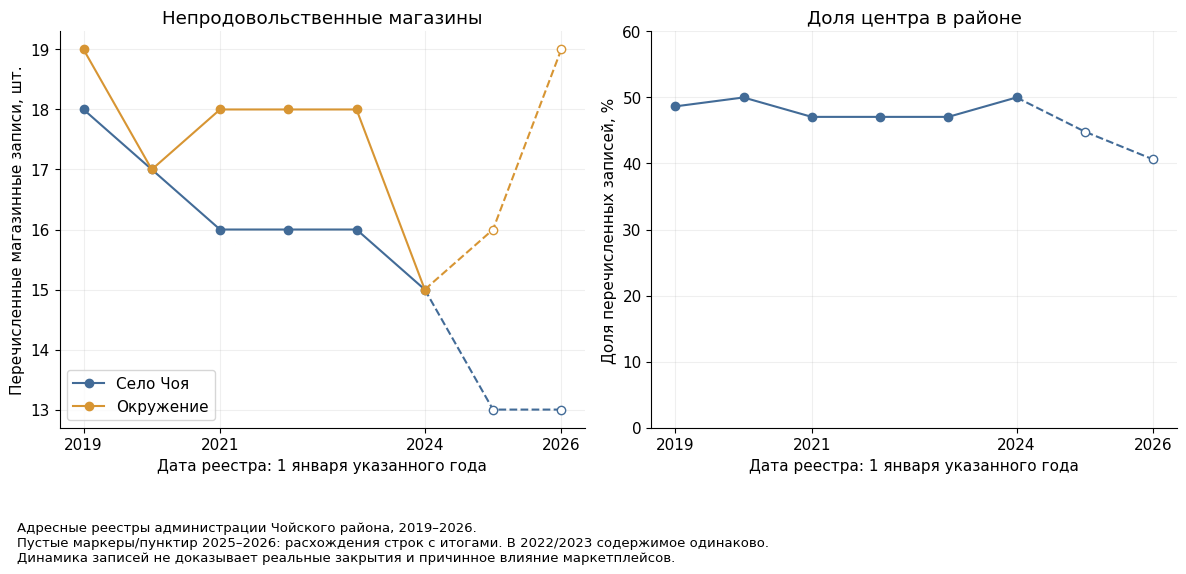

In [4]:
choya=pd.read_csv(ROOT/'choya_functional_concentration.csv')
display(choya[choya.category.isin(['all_observed','nonfood'])].round(2))
z=choya[choya.category.eq('nonfood')].sort_values('year')
solid=z[z.year.le(2024)]
late=z[z.year.ge(2024)]
fig,axes=plt.subplots(1,2,figsize=(12,5.8))
for field,label,color in [('centre_listed_entries','Село Чоя','#426b97'),
                         ('surrounding_listed_entries','Окружение','#d79533')]:
    axes[0].plot(solid.year,solid[field],marker='o',label=label,color=color)
    axes[0].plot(late.year,late[field],ls='--',color=color)
    uncertain=late[late.year.gt(2024)]
    axes[0].scatter(uncertain.year,uncertain[field],facecolors='white',edgecolors=color,zorder=3)
axes[0].set_ylabel('Перечисленные магазинные записи, шт.')
axes[0].set_title('Непродовольственные магазины')
axes[0].legend()
axes[1].plot(solid.year,solid.centre_share_pct,marker='o',color='#426b97')
axes[1].plot(late.year,late.centre_share_pct,ls='--',color='#426b97')
axes[1].scatter(uncertain.year,uncertain.centre_share_pct,facecolors='white',edgecolors='#426b97',zorder=3)
axes[1].set_ylabel('Доля перечисленных записей, %')
axes[1].set_title('Доля центра в районе')
axes[1].set_ylim(0,60)
for ax in axes:
    ax.set_xticks([2019,2021,2024,2026])
    ax.set_xlabel('Дата реестра: 1 января указанного года')
    ax.grid(alpha=.2)
fig.tight_layout()
fig.subplots_adjust(bottom=.25)
fig.text(.02,.02,'Адресные реестры администрации Чойского района, 2019–2026.\n'
         'Пустые маркеры/пунктир 2025–2026: расхождения строк с итогами. В 2022/2023 содержимое одинаково.\n'
         'Динамика записей не доказывает реальные закрытия и причинное влияние маркетплейсов.',fontsize=9.5)
fig.savefig(ROOT/'choya_trade_role.png',dpi=150)
plt.show()


## Сопоставление с рассредоточением получения товаров
Таблица связывает центр с положительной записью WB на обеих датах и чистое
изменение числа других НП с записями. Каталожный интервал 29.09.2022–11.03.2024
и торговый интервалIV2022–IV2024 различаются. Профили источников не полностью
гармонизированы. Это совместное описание, не «обработанная» и «контрольная» группы.
Сравнения учитывают радиусы и два профиля; они не оценивают причинность.

In [5]:
co=pd.read_csv(ROOT/'receipt_trade_descriptive_summary.csv')
display(co[(co.radius_km==5)&co.catalogue_profile.eq('allcatalog_objects')][
    ['category','receipt_category','centres_n','stock_decline_n',
     'share_loss_atleast1pp_n','share_gain_atleast1pp_n','median_trade_share_change_pp']].round(2))


,category,receipt_category,centres_n,stock_decline_n,share_loss_atleast1pp_n,share_gain_atleast1pp_n,median_trade_share_change_pp
4,Магазины,net_increase_in_other_positive_catalogue_NP,72,22,12,31,0.76
5,Магазины,no_net_increase_in_other_positive_catalogue_NP,76,24,9,43,1.36
16,Специализированные непродовольственные магазины,net_increase_in_other_positive_catalogue_NP,68,20,19,17,0.00
17,Специализированные непродовольственные магазины,no_net_increase_in_other_positive_catalogue_NP,70,17,5,7,0.00


## Полученная история Ozon
Два реальных официальных APIответа:19.03.2023 —3444ID,09.06.2024 —1885ID.
Первый покрывает Москву/Подмосковье, второй — более узкую часть Москвы.
Неизвестны исходные POSTviewport. Разность 3444→1885 не является сокращением сети.
Дополнительно получены 32 положительных геосвидетельства 2021–2025; это архивная
выборка, а не равномерная история России. Отдельный XLSX36958 адресов не имеет
подтверждённой даты наблюдения и не объявляется срезом 2025 по свойствам файла.
Даты архивирования не названы открытиями, отсутствие в архиве не значит отсутствия услуги.

In [6]:
oz=[]
for name in ['ozon_opp_api_positive_points_20230319.parquet',
             'ozon_opp_api_positive_points_20240609.parquet']:
    p=ROOT/'ozon'/name
    df=pd.read_parquet(p)
    oz.append({'Файл':name,'Записей':len(df)})
display(pd.DataFrame(oz))


,Файл,Записей
0,ozon_opp_api_positive_points_20230319.parquet,3444
1,ozon_opp_api_positive_points_20240609.parquet,1885


## Что теперь можно и чего нельзя заключить
Получены независимые исходы относительного веса центра. Сокращение запаса
магазинов и потеря доли в окружении не обязаны совпадать; то же верно для населения.
Распространение получения заказов вне центра может сосуществовать с его
демографической концентрацией и неодинаковой динамикой непродовольственных функций.

Фактический рост магазинов не доказывает отсутствия вытеснения: без маркетплейсов
рост мог быть выше. Падение также не доказывает причинности: есть иные процессы.
Нужны согласованные временные определения воздействия, подходящие сравнения,
проверка территориальных изменений и независимое подтверждение истории объектов.
Сейчас оценка «насколько ПВЗ вызвал изменение роли центра» ещё не идентифицирована.

Подробные результаты и оговорки: ROLE_RESULTS.txt. Расчёты и источник каждой
таблицы доступны в system/, bdmo/singleton/, shops/, ozon/ и корневых скриптах.
Покупательский опрос и невидимые потоки в обязательный дизайн не возвращались.